In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import shap
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
#from sklearn.linear_model import LogisticRegression
#from sklearn.tree import DecisionTreeClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Lasso
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import ElasticNetCV
from sklearn.linear_model import Ridge
#from xgboost import XGBClassifier
from sklearn.preprocessing import StandardScaler

In [4]:
# Load the data

In [29]:
#Data = pd.read_csv('/Users/blessingodeleye/Documents/VR_data/Labelled_data_set.csv')
Data = pd.read_csv('/Users/blessingodeleye/Documents/VR_data2/Data.csv')
Data = Data.iloc[:, 8:]

In [30]:
Data

,MotionToPhotonLatency,minMtpLatency,maxMtpLatency,avgMtpLatency,StdDev mtpLatency,mtpEntropy,currentRotation.x,currentRotation.y,currentRotation.z,currentRotation.w,pitch,yaw,roll
0,0.00,0.00,0.00,0.00,0.00,0.00,0.34,-0.10,-0.14,0.92,37.27,339.66,335.71
1,14.52,0.00,14.52,10.89,7.26,0.00,0.34,-0.10,-0.14,0.92,37.13,339.59,335.73
2,14.52,14.52,14.52,10.89,6.85,0.00,0.34,-0.10,-0.14,0.92,36.98,339.55,335.75
3,25.71,14.52,25.71,21.02,9.13,0.74,0.34,-0.10,-0.14,0.92,36.87,339.55,335.85
4,14.34,14.34,25.71,16.53,8.17,0.51,0.34,-0.10,-0.14,0.93,36.70,339.47,336.03
...,...,...,...,...,...,...,...,...,...,...,...,...,...
10327,27.34,27.34,115.84,69.43,30.18,1.34,0.34,-0.41,0.13,0.84,42.33,305.84,354.87
10328,91.25,27.34,91.25,69.45,30.29,0.89,0.34,-0.41,0.12,0.84,42.55,305.32,354.15
10329,85.24,85.24,91.25,69.47,29.81,0.00,0.35,-0.41,0.14,0.83,44.41,306.12,355.37
10330,42.76,42.76,85.24,69.44,32.61,0.96,0.36,-0.40,0.14,0.83,45.45,306.43,355.80


In [31]:
Data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10332 entries, 0 to 10331
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   MotionToPhotonLatency  10332 non-null  float64
 1   minMtpLatency          10332 non-null  float64
 2   maxMtpLatency          10332 non-null  float64
 3   avgMtpLatency          10332 non-null  float64
 4   StdDev mtpLatency      10332 non-null  float64
 5   mtpEntropy             10332 non-null  float64
 6   currentRotation.x      10332 non-null  float64
 7   currentRotation.y      10332 non-null  float64
 8   currentRotation.z      10332 non-null  float64
 9   currentRotation.w      10332 non-null  float64
 10  pitch                  10332 non-null  float64
 11  yaw                    10332 non-null  float64
 12  roll                   10332 non-null  float64
dtypes: float64(13)
memory usage: 1.0 MB


In [32]:
Data.head(10)

,MotionToPhotonLatency,minMtpLatency,maxMtpLatency,avgMtpLatency,StdDev mtpLatency,mtpEntropy,currentRotation.x,currentRotation.y,currentRotation.z,currentRotation.w,pitch,yaw,roll
0,0.00,0.00,0.00,0.00,0.00,0.00,0.34,-0.10,-0.14,0.92,37.27,339.66,335.71
1,14.52,0.00,14.52,10.89,7.26,0.00,0.34,-0.10,-0.14,0.92,37.13,339.59,335.73
2,14.52,14.52,14.52,10.89,6.85,0.00,0.34,-0.10,-0.14,0.92,36.98,339.55,335.75
3,25.71,14.52,25.71,21.02,9.13,0.74,0.34,-0.10,-0.14,0.92,36.87,339.55,335.85
4,14.34,14.34,25.71,16.53,8.17,0.51,0.34,-0.10,-0.14,0.93,36.70,339.47,336.03
5,12.84,12.84,14.34,14.32,4.70,0.14,0.34,-0.10,-0.14,0.93,36.49,339.33,336.17
6,14.41,12.84,14.41,14.37,4.71,0.15,0.33,-0.11,-0.14,0.93,36.22,339.10,336.32
7,14.69,14.41,14.69,14.53,4.70,0.19,0.33,-0.11,-0.14,0.93,35.86,338.75,336.44
8,14.34,14.34,14.69,14.45,0.65,0.18,0.33,-0.11,-0.13,0.93,35.46,338.31,336.46
9,12.37,12.37,14.34,13.60,0.94,0.20,0.33,-0.12,-0.13,0.93,35.04,337.75,336.37


In [38]:
Data.shape

(10332, 13)

In [39]:
# Select input features and target variable

In [40]:
X = Data.iloc[:, 0 :]
X.drop(['MotionToPhotonLatency'], axis=1, inplace=True)

In [41]:
y = Data['MotionToPhotonLatency']

In [42]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [43]:
#Scale data
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [44]:
# Fit a random forest regressor and get the feature importances

In [45]:
rf = RandomForestRegressor()
rf.fit(X_train, y_train)

RandomForestRegressor()

In [46]:
importances = rf.feature_importances_

In [47]:
indices = np.argsort(importances)[::-1]

In [48]:
# Get feature names
feature_names = X.columns

In [49]:
# Get feature names
feature_names = X.columns

In [50]:
# Print feature ranking
print("Feature ranking:")
for f in range(X.shape[1]):
    print("%d. feature %d (%f) - %s" % (f + 1, indices[f], importances[indices[f]], feature_names[indices[f]]))

Feature ranking:
1. feature 1 (0.780965) - maxMtpLatency
2. feature 0 (0.101576) - minMtpLatency
3. feature 3 (0.032559) - StdDev mtpLatency
4. feature 2 (0.016083) - avgMtpLatency
5. feature 11 (0.013568) - roll
6. feature 10 (0.013195) - yaw
7. feature 7 (0.009485) - currentRotation.z
8. feature 9 (0.008720) - pitch
9. feature 6 (0.007434) - currentRotation.y
10. feature 5 (0.006605) - currentRotation.x
11. feature 8 (0.005617) - currentRotation.w
12. feature 4 (0.004192) - mtpEntropy


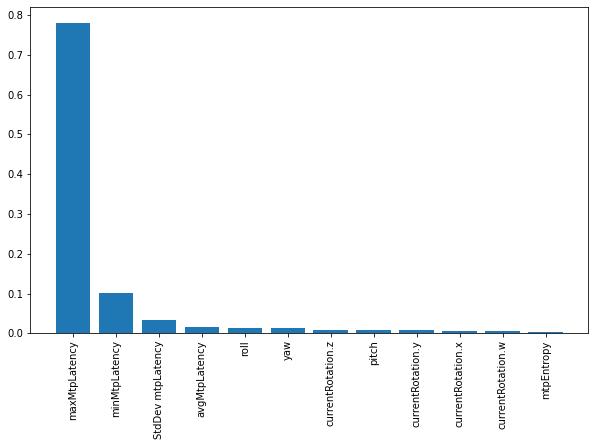

In [51]:
# Plot feature importances
plt.figure(figsize=(10, 6))
plt.bar(range(len(importances)), importances[indices])
plt.xticks(range(len(importances)), feature_names[indices], rotation=90)
plt.show()

In [52]:
# Calculate permutation importances

In [53]:
result_rf = permutation_importance(rf, X_test, y_test, n_repeats=50, random_state=42)

In [54]:
# Print feature ranking
sorted_idx = result_rf.importances_mean.argsort()[::-1]
for i in sorted_idx:
    print(f"{X.columns[i]:<15} {result_rf.importances_mean[i]:.3f} +/- {result_rf.importances_std[i]:.3f}")

maxMtpLatency   1.564 +/- 0.070
minMtpLatency   0.088 +/- 0.005
mtpEntropy      0.005 +/- 0.004
currentRotation.w 0.003 +/- 0.005
currentRotation.z -0.004 +/- 0.009
currentRotation.y -0.007 +/- 0.006
pitch           -0.008 +/- 0.006
currentRotation.x -0.008 +/- 0.007
roll            -0.009 +/- 0.010
avgMtpLatency   -0.011 +/- 0.003
yaw             -0.015 +/- 0.009
StdDev mtpLatency -0.043 +/- 0.004


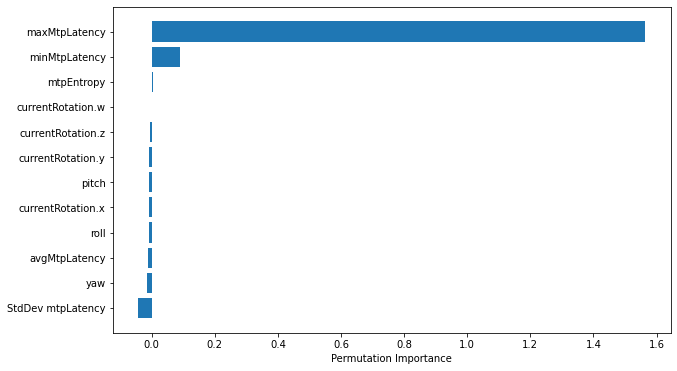

In [55]:
# Plot feature importances
plt.figure(figsize=(10, 6))
sorted_idx = result_rf.importances_mean.argsort()
plt.barh(range(X.shape[1]), result_rf.importances_mean[sorted_idx])
plt.yticks(range(X.shape[1]), X.columns[sorted_idx])
plt.xlabel("Permutation Importance")
plt.show()

In [56]:
# Fit a linear regression model

In [57]:
lr = LinearRegression()
lr.fit(X_train, y_train)

LinearRegression()

In [58]:
# Get the coefficient values and feature names
coef_lr = lr.coef_

In [59]:
feature_names = X.columns

In [60]:
'Feature ranking'
for i in range(len(feature_names)):
    print("%s: %f" % (feature_names[i], abs(coef_lr[i])))

minMtpLatency: 12.184956
maxMtpLatency: 22.550025
avgMtpLatency: 0.330880
StdDev mtpLatency: 0.337079
mtpEntropy: 0.439980
currentRotation.x: 0.009021
currentRotation.y: 0.010861
currentRotation.z: 0.019941
currentRotation.w: 0.028187
pitch: 0.064469
yaw: 0.046633
roll: 0.104057


In [61]:
# Print the feature importance in order of highest to lowest absolute coefficient values
print("Feature importance:")
sorted_indices = np.argsort(abs(coef_lr))[::-1]
for i in sorted_indices:
    print("%s: %f" % (feature_names[i], abs(coef_lr[i])))

Feature importance:
maxMtpLatency: 22.550025
minMtpLatency: 12.184956
mtpEntropy: 0.439980
StdDev mtpLatency: 0.337079
avgMtpLatency: 0.330880
roll: 0.104057
pitch: 0.064469
yaw: 0.046633
currentRotation.w: 0.028187
currentRotation.z: 0.019941
currentRotation.y: 0.010861
currentRotation.x: 0.009021


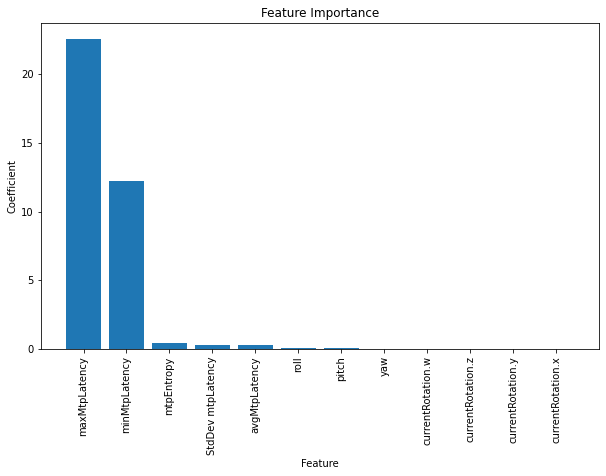

In [62]:
# Plot feature importance in order of highest to lowest absolute coefficient values
sorted_indices = np.argsort(abs(coef_lr))[::-1]
sorted_features = [feature_names[i] for i in sorted_indices]
sorted_coefficients = [abs(coef_lr[i]) for i in sorted_indices]

plt.figure(figsize=(10, 6))
plt.bar(sorted_features, sorted_coefficients)
plt.xticks(rotation=90)
plt.xlabel('Feature')
plt.ylabel('Coefficient')
plt.title('Feature Importance')
plt.show()

In [63]:
# Calculate permutation importances

In [64]:
result_lr = permutation_importance(lr, X_test, y_test, n_repeats=50, random_state=42)

In [65]:
# Print permutation importances
print("Permutation importances:")
for i in result_lr.importances_mean.argsort()[::-1]:
    print("%s: %f" % (feature_names[i], result_lr.importances_mean[i]))

Permutation importances:
maxMtpLatency: 0.819417
minMtpLatency: 0.215024
StdDev mtpLatency: 0.002853
avgMtpLatency: 0.001479
mtpEntropy: 0.000885
pitch: 0.000019
currentRotation.x: 0.000001
currentRotation.y: -0.000001
currentRotation.w: -0.000005
currentRotation.z: -0.000011
yaw: -0.000044
roll: -0.000072


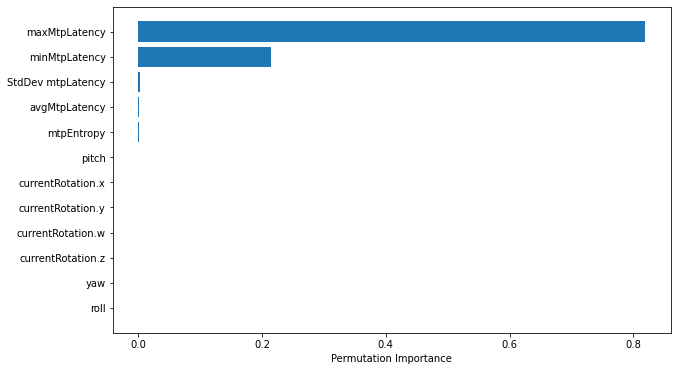

In [66]:
# Plot feature importances
plt.figure(figsize=(10, 6))
sorted_idx = result_lr.importances_mean.argsort()
plt.barh(range(X.shape[1]), result_lr.importances_mean[sorted_idx])
plt.yticks(range(X.shape[1]), X.columns[sorted_idx])
plt.xlabel("Permutation Importance")
plt.show()

In [67]:
#Lasso regression

In [68]:
l_reg = Lasso(alpha=0.2)
l_reg.fit(X_train, y_train)

Lasso(alpha=0.2)

In [69]:
l_reg_abs = abs(l_reg.coef_)

In [70]:
# Create a DataFrame to store the feature importance scores and names
feature_importance = pd.DataFrame({'Feature_names': X.columns, 'Importance': l_reg_abs})

In [71]:
# Sort the features by importance and print the ranked list
feature_importance = feature_importance.sort_values('Importance', ascending=False)

In [72]:
feature_importance

,Feature_names,Importance
1,maxMtpLatency,22.050643
0,minMtpLatency,11.831949
4,mtpEntropy,0.093415
2,avgMtpLatency,0.000000
3,StdDev mtpLatency,0.000000
5,currentRotation.x,0.000000
6,currentRotation.y,0.000000
7,currentRotation.z,0.000000
8,currentRotation.w,0.000000
9,pitch,0.000000


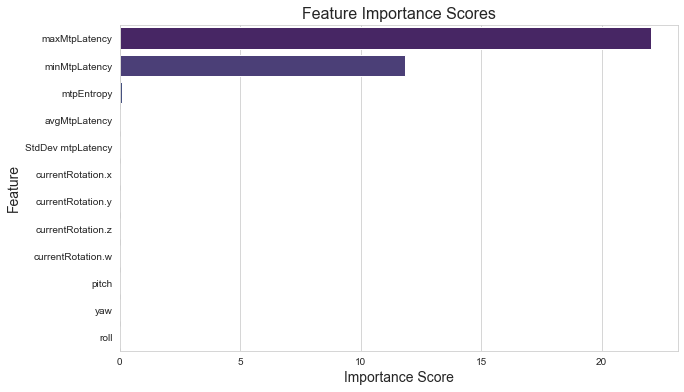

In [73]:
# Create a barplot of the feature importance scores>
plt.figure(figsize=(10, 6))
sns.set_style('whitegrid')
sns.barplot(x='Importance', y='Feature_names', data=feature_importance, palette='viridis')
plt.xlabel('Importance Score', fontsize=14)
plt.ylabel('Feature', fontsize=14)
plt.title('Feature Importance Scores', fontsize=16)
plt.show()

In [74]:
# Calculate permutation importances

In [75]:
result_l_reg= permutation_importance(l_reg, X_test, y_test, n_repeats=50, random_state=42)

In [76]:
# Print permutation importances
print("Permutation importances:")
for i in result_l_reg.importances_mean.argsort()[::-1]:
    print("%s: %f" % (feature_names[i], result_l_reg.importances_mean[i]))

Permutation importances:
maxMtpLatency: 0.783452
minMtpLatency: 0.203267
mtpEntropy: 0.000152
roll: 0.000000
yaw: 0.000000
pitch: 0.000000
currentRotation.w: 0.000000
currentRotation.z: 0.000000
currentRotation.y: 0.000000
currentRotation.x: 0.000000
StdDev mtpLatency: 0.000000
avgMtpLatency: 0.000000


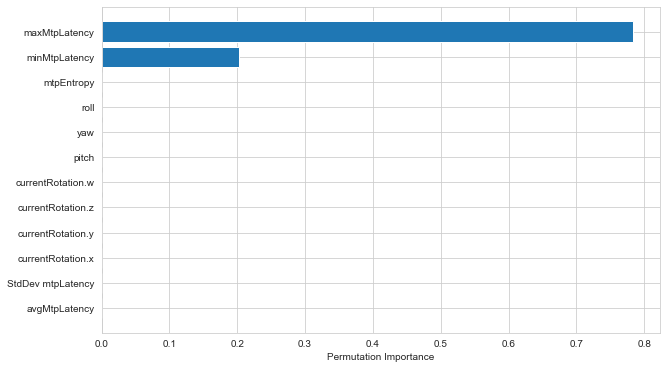

In [77]:
# Plot feature importances
plt.figure(figsize=(10, 6))
sorted_idx = result_l_reg.importances_mean.argsort()
plt.barh(range(X.shape[1]), result_l_reg.importances_mean[sorted_idx])
plt.yticks(range(X.shape[1]), X.columns[sorted_idx])
plt.xlabel("Permutation Importance")
plt.show()

In [78]:
#Elastic Net Feature Importance

In [79]:
# Create Elastic Net object
enet = ElasticNetCV(cv=5, random_state=0)
enet.fit(X_train, y_train)

ElasticNetCV(cv=5, random_state=0)

In [80]:
# Extract feature importance from coefficients
feature_importance = abs(enet.coef_)

In [81]:
# Normalize the feature importance scores
feature_importance_normalized = feature_importance / feature_importance.sum()

In [82]:
# Create a dictionary of feature names and their importance scores
features_dict = dict(zip(X.columns, feature_importance_normalized))

In [83]:
# Sort the dictionary in descending order of importance scores
sorted_features = sorted(features_dict.items(), key=lambda x: x[1], reverse=True)

In [84]:
# Print the feature importance scores
for feature in sorted_features:
    print(feature[0], ": ", feature[1])

maxMtpLatency :  0.5788661207247815
minMtpLatency :  0.36426137411476467
StdDev mtpLatency :  0.04325927849080805
mtpEntropy :  0.0050172216041834555
avgMtpLatency :  0.0035725204445912298
roll :  0.0024811057686338076
yaw :  0.0012744671361826802
pitch :  0.0006557748757922717
currentRotation.x :  0.00037253690424550787
currentRotation.w :  0.00023959993601665146
currentRotation.y :  0.0
currentRotation.z :  0.0


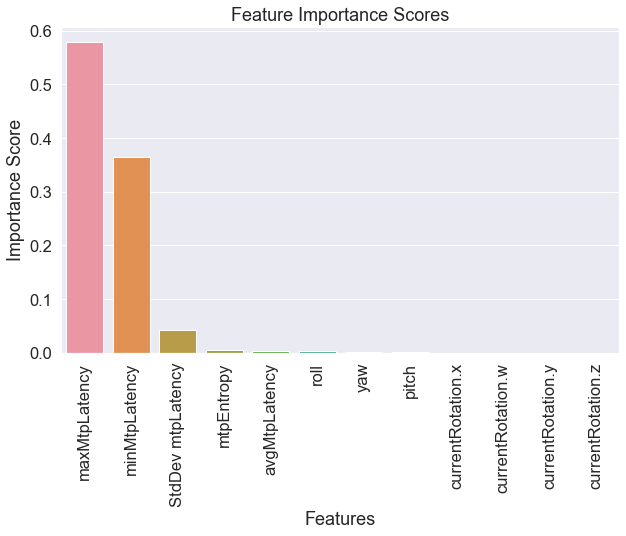

In [85]:
# Create a bar plot of feature importance scores
sns.set_style("whitegrid")
sns.set(font_scale=1.5)
fig, ax = plt.subplots(figsize=(10,6))
sns.barplot(x=[x[0] for x in sorted_features], y=[x[1] for x in sorted_features], ax=ax)
ax.set_title("Feature Importance Scores")
ax.set_xlabel("Features")
ax.set_ylabel("Importance Score")
plt.xticks(rotation=90)
plt.show()

In [86]:
# Calculate permutation importances

In [87]:
result_enet= permutation_importance(enet, X_test, y_test, n_repeats=50, random_state=42)

In [88]:
# Print permutation importances
print("Permutation importances:")
for i in result_enet.importances_mean.argsort()[::-1]:
    print("%s: %f" % (feature_names[i], result_enet.importances_mean[i]))

Permutation importances:
maxMtpLatency: 0.627862
minMtpLatency: 0.232027
mtpEntropy: 0.000238
pitch: 0.000008
currentRotation.x: 0.000003
currentRotation.z: -0.000000
currentRotation.y: -0.000000
currentRotation.w: -0.000002
yaw: -0.000034
roll: -0.000049
avgMtpLatency: -0.000423
StdDev mtpLatency: -0.006741


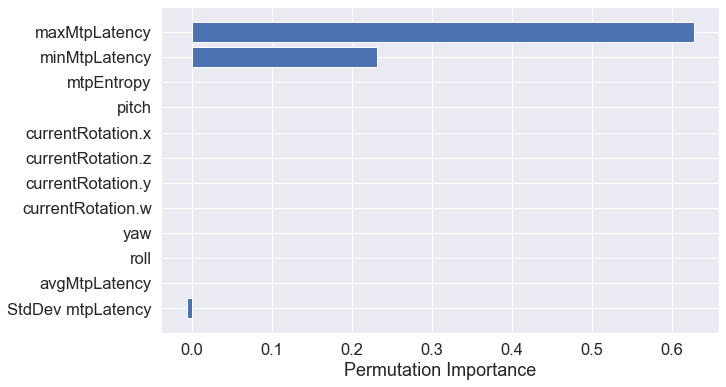

In [89]:
# Plot feature importances
plt.figure(figsize=(10, 6))
sorted_idx = result_enet.importances_mean.argsort()
plt.barh(range(X.shape[1]), result_enet.importances_mean[sorted_idx])
plt.yticks(range(X.shape[1]), X.columns[sorted_idx])
plt.xlabel("Permutation Importance")
plt.show()

In [90]:
# Ridge model

In [91]:
ridge = Ridge()
ridge.fit(X_train, y_train)

Ridge()

In [92]:
# Extract feature importance from coefficients
feature_importance = abs(ridge.coef_)

In [93]:
# Normalize the feature importance scores
feature_importance_normalized = feature_importance / feature_importance.sum()

In [94]:
# Create a dictionary of feature names and their importance scores
features_dict = dict(zip(X.columns, feature_importance_normalized))

In [95]:
# Sort the dictionary in descending order of importance scores
sorted_features = sorted(features_dict.items(), key=lambda x: x[1], reverse=True)

In [96]:
sorted_features

[('maxMtpLatency', 0.6242280947787859),
 ('minMtpLatency', 0.33756541952656033),
 ('mtpEntropy', 0.012162733541010638),
 ('avgMtpLatency', 0.009112052574187342),
 ('StdDev mtpLatency', 0.009092525701506015),
 ('roll', 0.0028822585178890085),
 ('pitch', 0.0017850532981910736),
 ('yaw', 0.0012949050394008097),
 ('currentRotation.w', 0.000783069744617293),
 ('currentRotation.z', 0.0005515681787599384),
 ('currentRotation.y', 0.00029619914325272205),
 ('currentRotation.x', 0.00024611995583902674)]

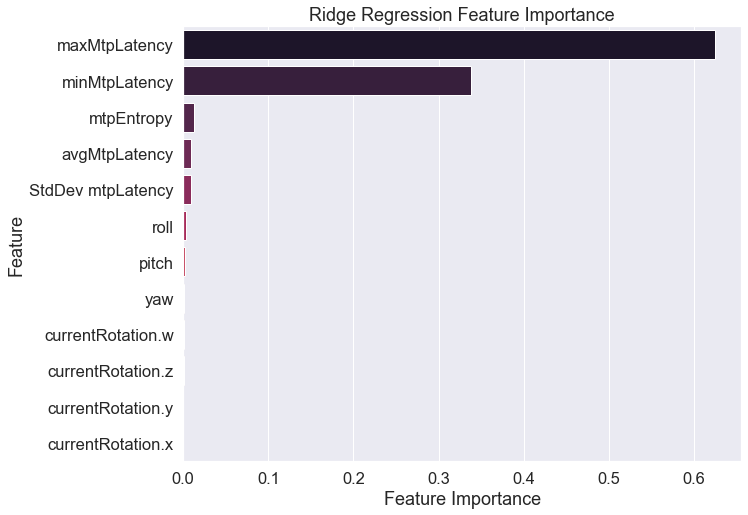

In [97]:
plt.figure(figsize = (10, 8))
sns.set_style("whitegrid")
sns.set(font_scale=1.5)
sns.barplot(x=[x[1] for x in sorted_features], y=[x[0] for x in sorted_features], palette="rocket")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Ridge Regression Feature Importance")
plt.show()

In [98]:
# Calculate permutation importances

In [99]:
result_ridge= permutation_importance(ridge, X_test, y_test, n_repeats=50, random_state=42)

In [100]:
# Print permutation importances
print("Permutation importances:")
for i in result_ridge.importances_mean.argsort()[::-1]:
    print("%s: %f" % (feature_names[i], result_ridge.importances_mean[i]))

Permutation importances:
maxMtpLatency: 0.818411
minMtpLatency: 0.215132
StdDev mtpLatency: 0.002772
avgMtpLatency: 0.001469
mtpEntropy: 0.000882
pitch: 0.000019
currentRotation.x: 0.000001
currentRotation.y: -0.000001
currentRotation.w: -0.000005
currentRotation.z: -0.000011
yaw: -0.000044
roll: -0.000072


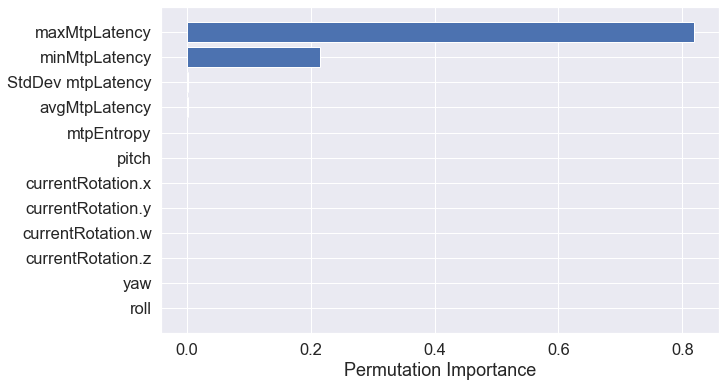

In [101]:
# Plot feature importances
plt.figure(figsize=(10, 6))
sorted_idx = result_ridge.importances_mean.argsort()
plt.barh(range(X.shape[1]), result_ridge.importances_mean[sorted_idx])
plt.yticks(range(X.shape[1]), X.columns[sorted_idx])
plt.xlabel("Permutation Importance")
plt.show()